In [36]:
import openseespy.opensees as ops
import numpy as np
import matplotlib.pyplot as plt

In [37]:
# ============================================================
# 导线与档距参数
# ============================================================

L = 300.0          # 档距，m
H1 = 30.0          # 左挂点高度，m
H2 = 30.0          # 右挂点高度，m

A = 4.0e-4         # 导线截面面积，m2
E = 7.0e10         # 弹性模量，Pa

n_seg = 60         # 导线离散段数
n_node = n_seg + 1

# ============================================================
# 荷载参数
# ============================================================

# 推荐直接使用单位长度重力，单位 N/m
# 例如某导线自重为 15 N/m
q_g = 15.0

# 重力加速度，用于把单位长度重力换算为单位长度质量。
g = 9.81

# ============================================================
# 目标弧垂与初始几何
# ============================================================

sag_target = 8.0        # 目标弧垂，m

# 初始几何下挠取目标弧垂附近，非线性静力迭代会更平滑。
initial_sag_guess = sag_target

# ============================================================
# 初始应力搜索范围
# ============================================================

# 用抛物线近似 T = q_g L^2 / (8 f) 估计初始张力，再换算为应力。
# 本例 sigma_est 约为 52.7 MPa；搜索区间需要包络目标弧垂。
sigma_est = q_g * L ** 2 / (8.0 * sag_target) / A
sigma_low = 0.75 * sigma_est     # Pa，较小应力，弧垂大
sigma_high = 1.50 * sigma_est    # Pa，较大应力，弧垂小

tol_sag = 1.0e-3        # 弧垂容许误差，m
max_iter = 40           # 最大外层二分迭代次数

In [38]:
def calculate_sag_relative_to_chord(final_coords, H1, H2, L):
    """
    计算相对于两端挂点连线的最大弧垂。

    final_coords:
        shape = (n_node, 3)
        每行是一个节点最终坐标 [x, y, z]

    弧垂定义：
        sag_i = chord_z(x_i) - z_i

    其中 chord_z 是两端挂点连线在 x_i 处的高度。
    """

    max_sag = -1.0e30

    for p in final_coords:
        x = p[0]
        z = p[2]

        chord_z = H1 + (H2 - H1) * x / L
        sag_i = chord_z - z

        if sag_i > max_sag:
            max_sag = sag_i

    return max_sag

In [39]:
def run_static_formfinding_with_init_stress(
    init_stress,
    L=300.0,
    H1=30.0,
    H2=30.0,
    A=4.0e-4,
    E=7.0e10,
    q_g=15.0,
    g=9.81,
    n_seg=60,
    initial_sag=0.2,
    n_steps=100,
    verbose=False,
):
    """
    给定 init_stress，建立导线模型，施加自重，进行静力非线性分析。

    返回：
        sag_final: 最终最大弧垂
        final_coords: 最终节点坐标
        axial_forces: 单元轴力
        ok: 分析是否成功
    """

    ops.wipe()

    # ============================================================
    # 1. 建立三维模型
    # ============================================================

    ops.model("basic", "-ndm", 3, "-ndf", 6)

    n_node = n_seg + 1

    # ============================================================
    # 2. 定义材料
    # ============================================================

    ops.uniaxialMaterial("Elastic", 1, E)
    E2 = 2.57e-3
    E3 = 1e+5
    ops.uniaxialMaterial("Elastic", 2, E2)
    ops.uniaxialMaterial("Elastic", 3, E3)

    # InitStressMaterial 中的 init_stress 是初始应力，单位 Pa
    ops.uniaxialMaterial("InitStressMaterial", 4, 1, init_stress)
    ops.section("Aggregator", 1, 4, "P", 2, "Mz", 2, "My", 3, "T")

    # ============================================================
    # 3. 建立节点
    # ============================================================

    for i in range(n_node):
        xi = i / n_seg

        x = L * xi
        y = 0.0

        # 两端挂点连线高度
        z_linear = H1 + (H2 - H1) * xi

        # 初始几何下挠是非线性迭代的起点，建议取目标弧垂附近。
        z = z_linear - 4.0 * initial_sag * xi * (1.0 - xi)

        ops.node(i + 1, x, y, z)

    # ============================================================
    # 4. 节点质量
    # ============================================================

    dx = L / n_seg
    mass_per_length = q_g / g

    for i in range(n_node):
        node_tag = i + 1

        if i == 0 or i == n_node - 1:
            trib_length = dx / 2.0
        else:
            trib_length = dx

        node_mass = mass_per_length * trib_length
        ops.mass(node_tag, node_mass, node_mass, node_mass, 0.0, 0.0, 0.0)

    # ============================================================
    # 5. 边界条件
    # ============================================================

    # corotTruss 只提供平动刚度；6 自由度节点的转动自由度需要约束，
    # 否则中间节点会出现零刚度转动自由度，导致刚度矩阵奇异。
    for node in range(1, n_node + 1):
        if node == 1 or node == n_node:
            ops.fix(node, 1, 1, 1, 1, 1, 1)
        else:
            ops.fix(node, 0, 0, 0, 1, 1, 1)

    # ============================================================
    # 6. 建立 corotTruss 单元
    # ============================================================

    for i in range(n_seg):
        ele_tag = i + 1
        i_node = i + 1
        j_node = i + 2

        ops.element(
            "corotTruss",
            ele_tag,
            i_node,
            j_node,
            A,
            4
        )

    # ============================================================
    # 7. 施加节点等效自重
    # ============================================================

    ops.timeSeries("Linear", 1)
    ops.pattern("Plain", 1, 1)

    dx = L / n_seg

    for i in range(n_node):
        node_tag = i + 1

        if i == 0 or i == n_node - 1:
            trib_length = dx / 2.0
        else:
            trib_length = dx

        weight = q_g * trib_length

        # 全局 Z 方向向下
        ops.load(node_tag, 0.0, 0.0, -weight, 0, 0, 0)

    # ============================================================
    # 8. 静力分析设置
    # ============================================================

    ops.constraints("Plain")
    ops.numberer("RCM")
    ops.system("BandGeneral")

    ops.test("NormDispIncr", 1.0e-8, 50)
    ops.algorithm("Newton")

    # 分 n_steps 步逐渐施加自重
    ops.integrator("LoadControl", 1.0 / n_steps)

    ops.analysis("Static")

    # ============================================================
    # 9. 执行静力分析
    # ============================================================

    ok_total = 0

    for step in range(n_steps):
        ok = ops.analyze(1)

        if ok != 0:
            if verbose:
                print(f"常规 Newton 不收敛，step = {step + 1}，尝试减小荷载步。")

            # 尝试减小荷载步
            ops.integrator("LoadControl", 1.0 / n_steps / 10.0)
            ok = ops.analyze(10)

            # 恢复原荷载步
            ops.integrator("LoadControl", 1.0 / n_steps)

            if ok != 0:
                ok_total = ok

                if verbose:
                    print(f"静力分析失败，init_stress = {init_stress:.6e}")

                break

    analysis_success = (ok_total == 0)

    # ============================================================
    # 10. 提取最终节点坐标
    # ============================================================

    final_coords = []

    for node in range(1, n_node + 1):
        coord = np.array(ops.nodeCoord(node), dtype=float)
        disp = np.array(ops.nodeDisp(node), dtype=float)
        trans_disp = disp[: coord.size]
        final_coord = coord + trans_disp
        final_coords.append(final_coord)

    final_coords = np.array(final_coords)

    # ============================================================
    # 11. 计算最终弧垂
    # ============================================================

    sag_final = calculate_sag_relative_to_chord(final_coords, H1, H2, L)

    # ============================================================
    # 12. 提取单元轴力
    # ============================================================

    axial_forces = []

    for ele in range(1, n_seg + 1):
        try:
            response = ops.eleResponse(ele, "axialForce")

            if isinstance(response, (list, tuple)) and len(response) > 0:
                axial_forces.append(response[0])
            else:
                axial_forces.append(np.nan)

        except Exception:
            axial_forces.append(np.nan)

    axial_forces = np.array(axial_forces, dtype=float)

    return sag_final, final_coords, axial_forces, analysis_success

In [40]:
sigma_test = sigma_est  # 抛物线估算值，本例约 52.7 MPa

sag_test, coords_test, axial_test, success_test = run_static_formfinding_with_init_stress(
    init_stress=sigma_test,
    L=L,
    H1=H1,
    H2=H2,
    A=A,
    E=E,
    q_g=q_g,
    g=g,
    n_seg=n_seg,
    initial_sag=initial_sag_guess,
    n_steps=100,
    verbose=True,
)

print("分析是否成功:", success_test)
print("测试初始应力:", sigma_test, "Pa")
print("最终弧垂:", sag_test, "m")
print("等效初始张力:", sigma_test * A, "N")

分析是否成功: True
测试初始应力: 52734375.0 Pa
最终弧垂: 8.002525433575837 m
等效初始张力: 21093.75 N


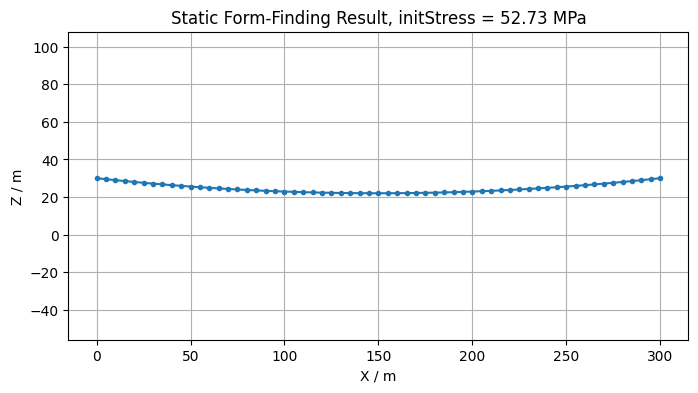

In [41]:
plt.figure(figsize=(8, 4))

plt.plot(coords_test[:, 0], coords_test[:, 2], marker="o", markersize=3)

plt.xlabel("X / m")
plt.ylabel("Z / m")
plt.title(f"Static Form-Finding Result, initStress = {sigma_test / 1e6:.2f} MPa")
plt.grid(True)
plt.axis("equal")
plt.show()

In [42]:
def formfind_by_target_sag_static(
    sag_target,
    sigma_low,
    sigma_high,
    tol_sag=1.0e-3,
    max_iter=40,
    **kwargs
):
    """
    使用二分法迭代 init_stress，使静力平衡后的最大弧垂接近 sag_target。
    """

    # ============================================================
    # 1. 先检查上下限是否包络目标弧垂
    # ============================================================

    sag_low, coords_low, axial_low, success_low = run_static_formfinding_with_init_stress(
        init_stress=sigma_low,
        **kwargs
    )

    sag_high, coords_high, axial_high, success_high = run_static_formfinding_with_init_stress(
        init_stress=sigma_high,
        **kwargs
    )

    print("初始区间检查：")
    print(f"sigma_low  = {sigma_low:.6e} Pa, sag_low  = {sag_low:.6f} m, success = {success_low}")
    print(f"sigma_high = {sigma_high:.6e} Pa, sag_high = {sag_high:.6f} m, success = {success_high}")
    print(f"sag_target = {sag_target:.6f} m")
    print()

    if not success_low:
        raise RuntimeError("sigma_low 对应的静力分析失败，请调整 sigma_low 或分析参数。")

    if not success_high:
        raise RuntimeError("sigma_high 对应的静力分析失败，请调整 sigma_high 或分析参数。")

    # 正常情况下：
    # sigma_low 较小，弧垂较大；
    # sigma_high 较大，弧垂较小。
    if not (sag_low >= sag_target >= sag_high):
        raise ValueError(
            "当前 sigma_low 和 sigma_high 没有包络目标弧垂。\n"
            "通常需要满足：sag_low >= sag_target >= sag_high。\n"
            "如果 sag_low < sag_target，说明 sigma_low 仍然太大；\n"
            "如果 sag_high > sag_target，说明 sigma_high 仍然太小。"
        )

    # ============================================================
    # 2. 开始二分
    # ============================================================

    history = []
    best_result = None

    print("二分迭代过程：")
    print(
        f"{'iter':>6s} | "
        f"{'initStress/MPa':>16s} | "
        f"{'sag/m':>12s} | "
        f"{'error/m':>12s} | "
        f"{'success':>8s}"
    )
    print("-" * 68)

    for it in range(1, max_iter + 1):
        sigma_mid = 0.5 * (sigma_low + sigma_high)

        sag_mid, coords_mid, axial_mid, success_mid = run_static_formfinding_with_init_stress(
            init_stress=sigma_mid,
            **kwargs
        )

        error = sag_mid - sag_target

        history.append({
            "iteration": it,
            "init_stress": sigma_mid,
            "sag": sag_mid,
            "error": error,
            "success": success_mid
        })

        print(
            f"{it:6d} | "
            f"{sigma_mid / 1e6:16.6f} | "
            f"{sag_mid:12.6f} | "
            f"{error:12.6e} | "
            f"{str(success_mid):>8s}"
        )

        if not success_mid:
            raise RuntimeError(
                f"二分过程中静力分析失败，iteration = {it}, init_stress = {sigma_mid:.6e} Pa"
            )

        best_result = {
            "init_stress": sigma_mid,
            "sag": sag_mid,
            "error": error,
            "final_coords": coords_mid,
            "axial_forces": axial_mid,
            "success": success_mid,
            "iteration": it,
            "history": history,
        }

        if abs(error) < tol_sag:
            print("\n满足弧垂误差要求，二分结束。")
            return best_result

        if sag_mid > sag_target:
            # 弧垂偏大，说明张力偏小，需要增大 init_stress
            sigma_low = sigma_mid
        else:
            # 弧垂偏小，说明张力偏大，需要减小 init_stress
            sigma_high = sigma_mid

    print("\n达到最大迭代次数，返回当前结果。")
    return best_result

In [43]:
result = formfind_by_target_sag_static(
    sag_target=sag_target,
    sigma_low=sigma_low,
    sigma_high=sigma_high,
    tol_sag=tol_sag,
    max_iter=max_iter,
    L=L,
    H1=H1,
    H2=H2,
    A=A,
    E=E,
    q_g=q_g,
    g=g,
    n_seg=n_seg,
    initial_sag=initial_sag_guess,
    n_steps=100,
    verbose=False,
)

初始区间检查：
sigma_low  = 3.955078e+07 Pa, sag_low  = 8.331897 m, success = True
sigma_high = 7.910156e+07 Pa, sag_high = 7.323456 m, success = True
sag_target = 8.000000 m

二分迭代过程：
  iter |   initStress/MPa |        sag/m |      error/m |  success
--------------------------------------------------------------------
     1 |        59.326172 |     7.835258 | -1.647419e-01 |     True
     2 |        49.438477 |     8.085516 | 8.551633e-02 |     True
     3 |        54.382324 |     7.960869 | -3.913117e-02 |     True
     4 |        51.910400 |     8.023313 | 2.331350e-02 |     True
     5 |        53.146362 |     7.992121 | -7.878664e-03 |     True
     6 |        52.528381 |     8.007725 | 7.724967e-03 |     True
     7 |        52.837372 |     7.999925 | -7.496199e-05 |     True

满足弧垂误差要求，二分结束。


In [44]:
print("\n================ 最终找形结果 ================")
print(f"目标弧垂 sag_target       = {sag_target:.6f} m")
print(f"最终弧垂 sag_final        = {result['sag']:.6f} m")
print(f"弧垂误差 error            = {result['error']:.6e} m")
print(f"迭代得到 initStress       = {result['init_stress']:.6e} Pa")
print(f"迭代得到 initStress       = {result['init_stress'] / 1e6:.6f} MPa")
print(f"等效初始张力 T0           = {result['init_stress'] * A:.6f} N")
print(f"静力分析是否成功          = {result['success']}")
print(f"外层二分迭代次数          = {result['iteration']}")

axial = result["axial_forces"]

print("\n单元轴力统计：")
print(f"N_min = {np.nanmin(axial):.6f} N")
print(f"N_max = {np.nanmax(axial):.6f} N")
print(f"N_avg = {np.nanmean(axial):.6f} N")


================ 最终找形结果 ================
目标弧垂 sag_target       = 8.000000 m
最终弧垂 sag_final        = 7.999925 m
弧垂误差 error            = -7.496199e-05 m
迭代得到 initStress       = 5.283737e+07 Pa
迭代得到 initStress       = 52.837372 MPa
等效初始张力 T0           = 21134.948730 N
静力分析是否成功          = True
外层二分迭代次数          = 7

单元轴力统计：
N_min = 21093.996405 N
N_max = 21209.677846 N
N_avg = 21133.883631 N


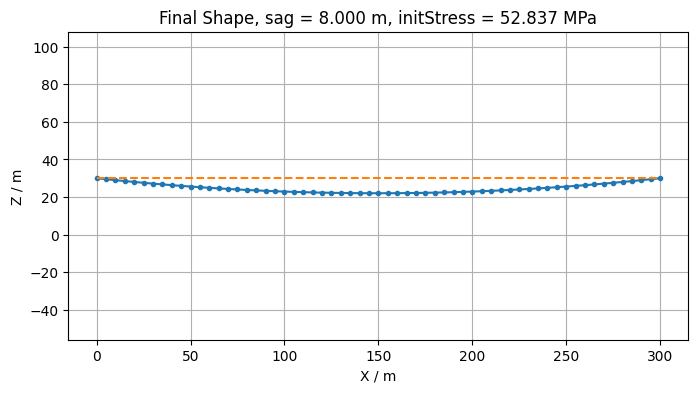

In [45]:
final_coords = result["final_coords"]

plt.figure(figsize=(8, 4))

plt.plot(final_coords[:, 0], final_coords[:, 2], marker="o", markersize=3)

# 挂点连线
x_chord = np.array([0.0, L])
z_chord = np.array([H1, H2])
plt.plot(x_chord, z_chord, linestyle="--")

plt.xlabel("X / m")
plt.ylabel("Z / m")
plt.title(
    f"Final Shape, sag = {result['sag']:.3f} m, "
    f"initStress = {result['init_stress'] / 1e6:.3f} MPa"
)
plt.grid(True)
plt.axis("equal")
plt.show()

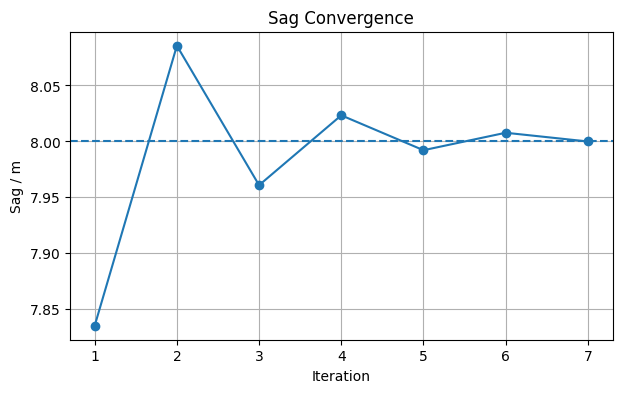

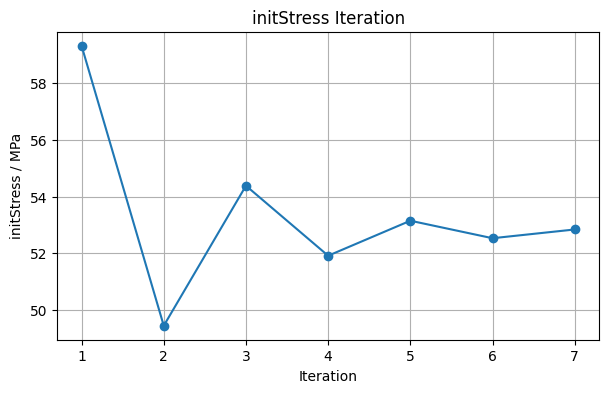

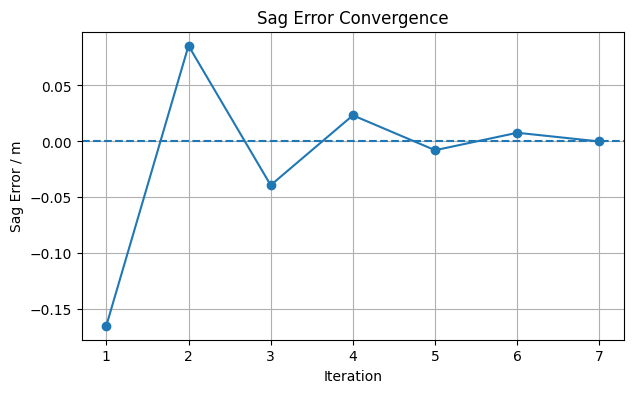

In [46]:
history = result["history"]

iters = [h["iteration"] for h in history]
sags = [h["sag"] for h in history]
errors = [h["error"] for h in history]
stresses = [h["init_stress"] / 1e6 for h in history]

plt.figure(figsize=(7, 4))
plt.plot(iters, sags, marker="o")
plt.axhline(sag_target, linestyle="--")
plt.xlabel("Iteration")
plt.ylabel("Sag / m")
plt.title("Sag Convergence")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(iters, stresses, marker="o")
plt.xlabel("Iteration")
plt.ylabel("initStress / MPa")
plt.title("initStress Iteration")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(iters, errors, marker="o")
plt.axhline(0.0, linestyle="--")
plt.xlabel("Iteration")
plt.ylabel("Sag Error / m")
plt.title("Sag Error Convergence")
plt.grid(True)
plt.show()

In [47]:
print(f"{'node':>6s} | {'x/m':>12s} | {'y/m':>12s} | {'z/m':>12s}")
print("-" * 52)

for i, p in enumerate(final_coords, start=1):
    print(f"{i:6d} | {p[0]:12.6f} | {p[1]:12.6f} | {p[2]:12.6f}")

  node |          x/m |          y/m |          z/m
----------------------------------------------------
     1 |     0.000000 |     0.000000 |    30.000000
     2 |     5.000014 |     0.000000 |    29.475559
     3 |    10.000026 |     0.000000 |    28.968897
     4 |    15.000038 |     0.000000 |    28.480012
     5 |    20.000047 |     0.000000 |    28.008904
     6 |    25.000056 |     0.000000 |    27.555575
     7 |    30.000063 |     0.000000 |    27.120023
     8 |    35.000069 |     0.000000 |    26.702249
     9 |    40.000074 |     0.000000 |    26.302253
    10 |    45.000078 |     0.000000 |    25.920034
    11 |    50.000081 |     0.000000 |    25.555593
    12 |    55.000083 |     0.000000 |    25.208930
    13 |    60.000084 |     0.000000 |    24.880044
    14 |    65.000084 |     0.000000 |    24.568936
    15 |    70.000084 |     0.000000 |    24.275606
    16 |    75.000082 |     0.000000 |    24.000053
    17 |    80.000080 |     0.000000 |    23.742278
    18 |   

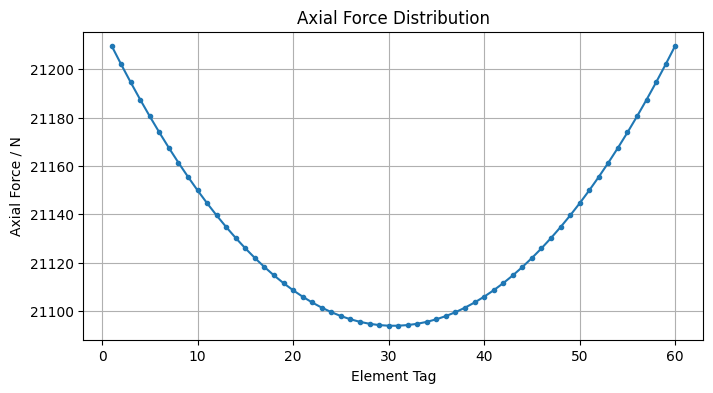

In [48]:
axial = result["axial_forces"]

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(axial) + 1), axial, marker="o", markersize=3)
plt.xlabel("Element Tag")
plt.ylabel("Axial Force / N")
plt.title("Axial Force Distribution")
plt.grid(True)
plt.show()

In [49]:
def run_modal_analysis(num_modes=6):
    """
    在当前 OpenSees 模型上进行模态分析。

    需要先完成静力找形；run_static_formfinding_with_init_stress 已根据 q_g / g
    给节点定义平动质量，因此找形完成后的模型可以直接用于 eigen 分析。
    """

    ops.wipeAnalysis()

    try:
        eigenvalues = np.array(ops.eigen(num_modes), dtype=float)
    except Exception:
        eigenvalues = np.array(ops.eigen("-fullGenLapack", num_modes), dtype=float)

    omega = np.full_like(eigenvalues, np.nan, dtype=float)
    positive = eigenvalues > 0.0
    omega[positive] = np.sqrt(eigenvalues[positive])

    frequencies = omega / (2.0 * np.pi)
    periods = np.full_like(frequencies, np.inf, dtype=float)
    valid_freq = frequencies > 0.0
    periods[valid_freq] = 1.0 / frequencies[valid_freq]

    node_tags = sorted(ops.getNodeTags())
    mode_shapes = np.zeros((len(eigenvalues), len(node_tags), 3), dtype=float)

    for mode_index in range(len(eigenvalues)):
        mode_tag = mode_index + 1

        for node_index, node_tag in enumerate(node_tags):
            eigenvector = np.array(ops.nodeEigenvector(node_tag, mode_tag), dtype=float)
            mode_shapes[mode_index, node_index, :] = eigenvector[:3]

        scale = np.max(np.linalg.norm(mode_shapes[mode_index], axis=1))
        if scale > 0.0:
            mode_shapes[mode_index] /= scale

    return {
        "eigenvalues": eigenvalues,
        "omega": omega,
        "frequencies": frequencies,
        "periods": periods,
        "mode_shapes": mode_shapes,
        "node_tags": node_tags,
    }


In [50]:
num_modes = 6

modal_result = run_modal_analysis(num_modes=num_modes)

print("\n================ 模态分析结果 ================")
print(f"{'mode':>6s} | {'lambda':>14s} | {'omega/(rad/s)':>14s} | {'freq/Hz':>12s} | {'period/s':>12s} | {'dominant':>10s}")
print("-" * 91)

component_names = ["X", "Y", "Z"]

for i in range(len(modal_result["frequencies"])):
    shape = modal_result["mode_shapes"][i]
    component_amp = np.max(np.abs(shape), axis=0)
    dominant_component = component_names[int(np.argmax(component_amp))]

    print(
        f"{i + 1:6d} | "
        f"{modal_result['eigenvalues'][i]:14.6e} | "
        f"{modal_result['omega'][i]:14.6f} | "
        f"{modal_result['frequencies'][i]:12.6f} | "
        f"{modal_result['periods'][i]:12.6f} | "
        f"{dominant_component:>10s}"
    )



================ 模态分析结果 ================
  mode |         lambda |  omega/(rad/s) |      freq/Hz |     period/s |   dominant
-------------------------------------------------------------------------------------------
     1 |   1.512494e+00 |       1.229835 |     0.195734 |     5.108967 |          Y
     2 |   6.011281e+00 |       2.451791 |     0.390215 |     2.562692 |          Z
     3 |   6.045833e+00 |       2.458828 |     0.391335 |     2.555358 |          Y
     4 |   7.942209e+00 |       2.818193 |     0.448529 |     2.229509 |          Z
     5 |   1.358759e+01 |       3.686135 |     0.586667 |     1.704546 |          Y
     6 |   1.527743e+01 |       3.908635 |     0.622079 |     1.607514 |          Z


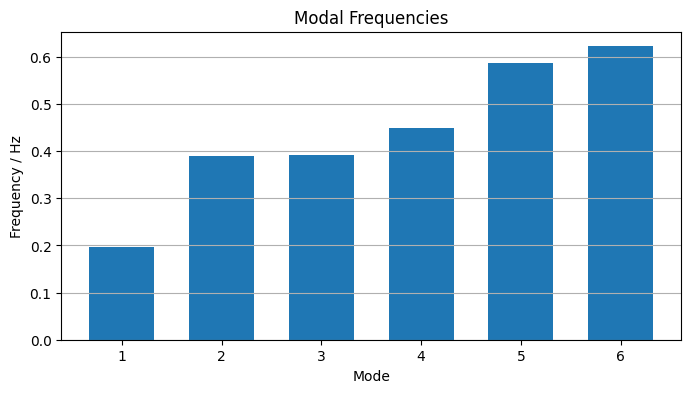

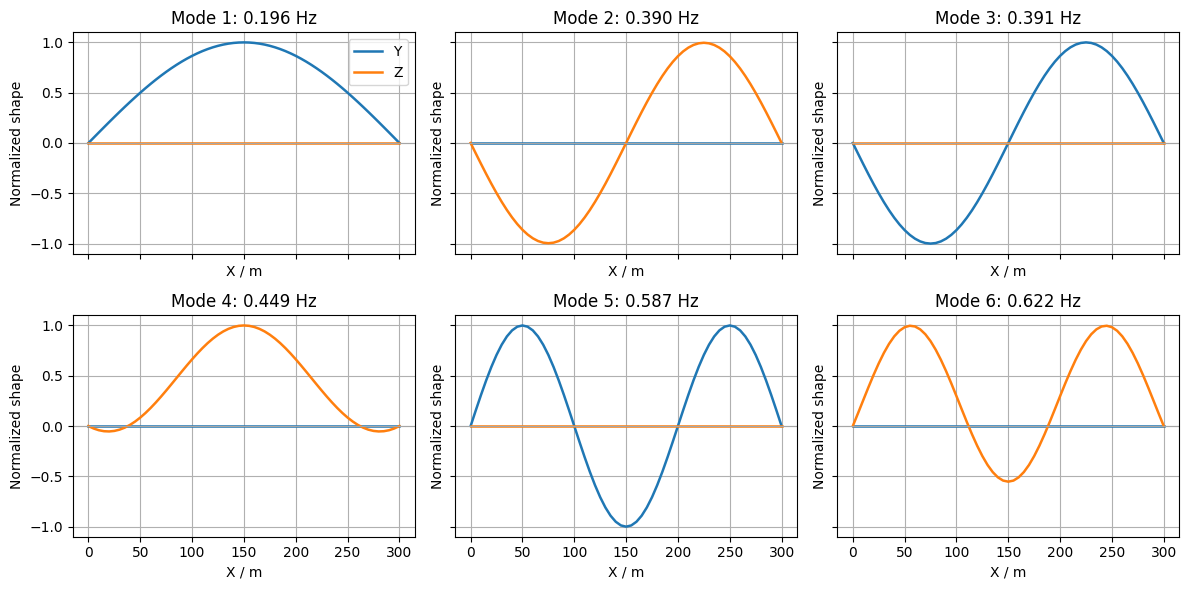

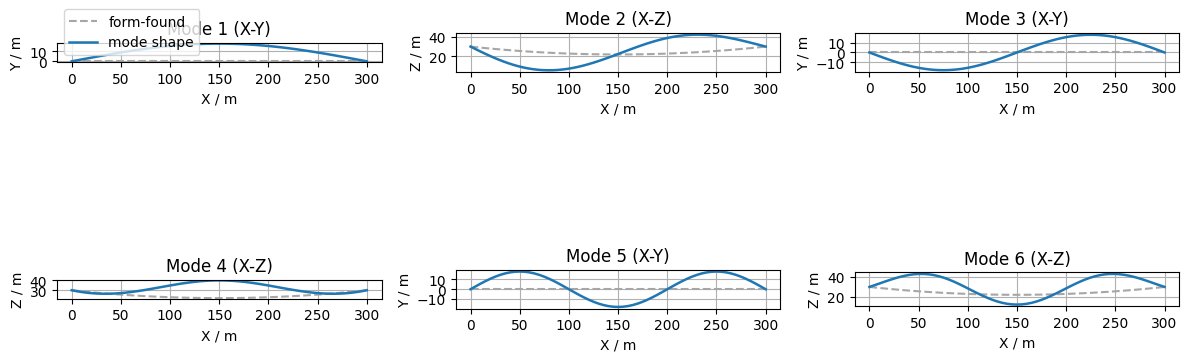

In [51]:
mode_ids = np.arange(1, len(modal_result["frequencies"]) + 1)

plt.figure(figsize=(8, 4))
plt.bar(mode_ids, modal_result["frequencies"], width=0.65)
plt.xlabel("Mode")
plt.ylabel("Frequency / Hz")
plt.title("Modal Frequencies")
plt.xticks(mode_ids)
plt.grid(True, axis="y")
plt.show()

x_modal = final_coords[:, 0]
n_plot = len(modal_result["frequencies"])
n_col = 3
n_row = int(np.ceil(n_plot / n_col))

fig, axes = plt.subplots(
    n_row,
    n_col,
    figsize=(12, 3.0 * n_row),
    sharex=True,
    sharey=True,
)
axes = np.atleast_1d(axes).ravel()

for i, ax in enumerate(axes):
    if i >= n_plot:
        ax.axis("off")
        continue

    shape = modal_result["mode_shapes"][i]

    ax.plot(x_modal, shape[:, 1], label="Y", linewidth=1.8)
    ax.plot(x_modal, shape[:, 2], label="Z", linewidth=1.8)
    ax.axhline(0.0, color="0.65", linewidth=0.8)
    ax.set_title(f"Mode {i + 1}: {modal_result['frequencies'][i]:.3f} Hz")
    ax.set_xlabel("X / m")
    ax.set_ylabel("Normalized shape")
    ax.grid(True)

    if i == 0:
        ax.legend()

plt.tight_layout()
plt.show()

mode_scale = 0.06 * L
n_deformed_plot = min(6, n_plot)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(12, 6.0),
)
axes = np.atleast_1d(axes).ravel()

for i, ax in enumerate(axes):
    if i >= n_deformed_plot:
        ax.axis("off")
        continue

    shape = modal_result["mode_shapes"][i]
    y_amp = np.max(np.abs(shape[:, 1]))
    z_amp = np.max(np.abs(shape[:, 2]))

    if y_amp > z_amp:
        base = final_coords[:, 1]
        deformed = final_coords[:, 1] + mode_scale * shape[:, 1]
        ylabel = "Y / m"
        plane = "X-Y"
    else:
        base = final_coords[:, 2]
        deformed = final_coords[:, 2] + mode_scale * shape[:, 2]
        ylabel = "Z / m"
        plane = "X-Z"

    ax.plot(final_coords[:, 0], base, color="0.65", linestyle="--", label="form-found")
    ax.plot(
        final_coords[:, 0] + mode_scale * shape[:, 0],
        deformed,
        linewidth=1.8,
        label="mode shape",
    )
    ax.set_title(f"Mode {i + 1} ({plane})")
    ax.set_xlabel("X / m")
    ax.set_ylabel(ylabel)
    ax.grid(True)
    ax.set_aspect("equal", adjustable="box")

    if i == 0:
        ax.legend()

plt.tight_layout()
plt.show()
